In [1]:
# Install kaggle package
!pip install -q kaggle

In [2]:
# Upload Kaggle Api (kaggle.json) to Colab
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"ronokrahman","key":"878830fca2f4d6df77f2511c571bc4bb"}'}

In [3]:
# Configure the kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [4]:
# Now Download the Dataset from kaggle using Dataset IDs
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:02<00:00, 80.7MB/s]



In [5]:
# Now Unzip the dataset
!unzip -q brain-tumor-mri-dataset -d /content/

In [45]:
# Import Required Libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader,  Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from torchvision.models import  densenet121, DenseNet121_Weights
import matplotlib.pyplot as plt
from tqdm import tqdm
import timm
from collections import Counter
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
import seaborn as sns
import numpy as np
import os
import copy


In [46]:
# Check GPU availability
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Available Device is: {device}')

Available Device is: cuda


In [47]:
# Create path variables for the dataset
train_dir = '/content/Training'
test_dir = '/content/Testing'

In [48]:
# Image Preprocessing
# Transform the training dataset
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],    # Here use image net normalization
        std=[0.229, 0.224, 0.225]
    )
])

In [49]:
# Validation and testing datset transformations
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [50]:
# Load the training images with different transformations
train_dataset_aug = datasets.ImageFolder(
    root=train_dir,
    transform=train_transform
)

train_dataset_eval = datasets.ImageFolder(
    root=train_dir,
    transform=test_transform
)

# Split indices into training (80%) and validation (20%)
indices = list(range(len(train_dataset_aug)))
labels = train_dataset_aug.targets

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Create the datasets
train_dataset = Subset(train_dataset_aug, train_indices)
val_dataset = Subset(train_dataset_eval, val_indices)

# Load the test dataset separately
test_dataset = datasets.ImageFolder(
    root=test_dir,
    transform=test_transform
)

# Check dataset sizes
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Classes:", train_dataset_aug.classes)

Training images: 4480
Validation images: 1120
Testing images: 1600
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [51]:
# Count labels in training dataset
from collections import Counter

# Count labels in the training subset
train_counts = Counter(
    train_dataset_aug.targets[i] for i in train_indices
)

# Print class-wise counts
for class_name, class_index in train_dataset_aug.class_to_idx.items():
    print(f"{class_name}: {train_counts[class_index]} images")

glioma: 1120 images
meningioma: 1120 images
notumor: 1120 images
pituitary: 1120 images


In [52]:
# Creates DataLoader to feed data to model
batch_size=32
train_loader=DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True
)
val_loader=DataLoader(
    dataset=val_dataset,
    batch_size=batch_size,
    shuffle=False
)
test_loader=DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [54]:
# Import DenseNet121 model

# Load pretrained AlexNet model
model = densenet121(
    weights=DenseNet121_Weights.DEFAULT
)

# Freeze all feature layers
for param in model.parameters():
    param.requires_grad = False

# Replace the final classifier layer 4 classes
model.classifier = nn.Linear(
    model.classifier.in_features,
    4
)

# Move model to device
model = model.to(device)

In [55]:
# 1. Create the loss function
criterion = nn.CrossEntropyLoss()

# 2. Create the optimizer
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001,
    weight_decay=0.0001
)

# 3. Create the learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=5
)

# 4. Create GradScaler for mixed-precision training
scaler = torch.amp.GradScaler(
    'cuda',
    enabled=(device.type == 'cuda')
)

In [56]:
# Build a Training Settings
epochs=20
patience=5
best_acc=0
counter=0

train_loss_history=[]
val_loss_history=[]
train_acc_history=[]
val_acc_history=[]

# Copy the best weights
best_weights=copy.deepcopy(model.state_dict())

In [57]:
# Train the DenseNet121 model

for epoch in range(epochs):

    print(f"\nEpoch {epoch + 1}/{epochs}")

    # =========================
    # 1. Training Phase
    # =========================
    model.train()

    running_loss = 0.0
    running_correct = 0

    train_bar = tqdm(train_loader, desc="Training")

    for images, labels in train_bar:

        # Move images and labels to device
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass and loss calculation
        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == 'cuda')
        ):

            outputs = model(images)

            # DenseNet121 returns a tensor directly
            loss = criterion(outputs, labels)

        # Backpropagation
        scaler.scale(loss).backward()

        # Update model parameters
        scaler.step(optimizer)

        # Update gradient scaler
        scaler.update()

        # Get predicted classes
        _, preds = torch.max(outputs, dim=1)

        # Accumulate loss and correct predictions
        running_loss += loss.item() * images.size(0)
        running_correct += (preds == labels).sum().item()

        # Update progress bar
        train_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{running_correct / ((train_bar.n + 1) * train_loader.batch_size):.4f}"
        )

    # Calculate average training loss and accuracy
    epoch_train_loss = running_loss / len(train_dataset)
    epoch_train_acc = running_correct / len(train_dataset)

    # =========================
    # 2. Validation Phase
    # =========================
    model.eval()

    val_loss = 0.0
    val_correct = 0

    with torch.no_grad():

        val_bar = tqdm(val_loader, desc="Validation")

        for images, labels in val_bar:

            # Move images and labels to device
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == 'cuda')
            ):

                outputs = model(images)

                # Calculate validation loss
                loss = criterion(outputs, labels)

            # Get predicted classes
            _, preds = torch.max(outputs, dim=1)

            # Accumulate loss and correct predictions
            val_loss += loss.item() * images.size(0)
            val_correct += (preds == labels).sum().item()

    # Calculate average validation loss and accuracy
    epoch_val_loss = val_loss / len(val_dataset)
    epoch_val_acc = val_correct / len(val_dataset)

    # =========================
    # 3. Update Learning Rate
    # =========================
    scheduler.step(epoch_val_loss)

    # =========================
    # 4. Save Training History
    # =========================
    train_loss_history.append(epoch_train_loss)
    val_loss_history.append(epoch_val_loss)

    train_acc_history.append(epoch_train_acc)
    val_acc_history.append(epoch_val_acc)

    # Print epoch results
    print(
        f"Train Loss: {epoch_train_loss:.4f}, "
        f"Train Acc: {epoch_train_acc:.4f}"
    )

    print(
        f"Val Loss: {epoch_val_loss:.4f}, "
        f"Val Acc: {epoch_val_acc:.4f}"
    )

    print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.7f}")

    # =========================
    # 5. Save the Best Model
    # =========================
    if epoch_val_acc > best_acc:

        best_acc = epoch_val_acc

        best_weights = copy.deepcopy(model.state_dict())

        torch.save(best_weights, 'best_DenseNet121_weights.pth')

        counter = 0

        print("Best DenseNet121 model saved!")

    else:
        counter += 1

    # =========================
    # 6. Early Stopping
    # =========================
    if counter >= patience:

        print("Early stopping triggered!")
        break

print(f"\nBest Validation Accuracy: {best_acc:.4f}")


Epoch 1/20


Validation: 100%|██████████| 35/35 [00:07<00:00,  4.54it/s]


Train Loss: 1.2529, Train Acc: 0.4743
Val Loss: 1.1151, Val Acc: 0.6304
Learning Rate: 0.0001000
Best DenseNet121 model saved!

Epoch 2/20


Validation: 100%|██████████| 35/35 [00:07<00:00,  4.62it/s]


Train Loss: 0.9764, Train Acc: 0.7174
Val Loss: 0.9164, Val Acc: 0.7616
Learning Rate: 0.0001000
Best DenseNet121 model saved!

Epoch 3/20


Validation: 100%|██████████| 35/35 [00:06<00:00,  5.11it/s]


... (31 outputs left out)

Validation: 100%|██████████| 35/35 [00:07<00:00,  4.55it/s]


Train Loss: 0.4188, Train Acc: 0.8598
Val Loss: 0.4095, Val Acc: 0.8795
Learning Rate: 0.0001000

Epoch 20/20


Validation: 100%|██████████| 35/35 [00:07<00:00,  4.63it/s]


Train Loss: 0.4035, Train Acc: 0.8645
Val Loss: 0.3952, Val Acc: 0.8848
Learning Rate: 0.0001000
Best DenseNet121 model saved!

Best Validation Accuracy: 0.8848


In [58]:
# Load the Best Model weights
model.load_state_dict(best_weights)

<All keys matched successfully>

In [59]:
# Test the DenseNet121 model on the test dataset
model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():

    for images, labels in test_loader:

        # Move images and labels to the device
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass through DenseNet121
        outputs = model(images)

        # Convert logits into probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Get predicted class indices
        _, preds = torch.max(outputs, dim=1)

        # Store actual and predicted labels
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

        # Store probabilities for all four classes
        y_prob.extend(probabilities.cpu().numpy())

In [60]:
# Test Accuracy
test_acc=accuracy_score(y_true, y_pred)
print(f'Test Accuracy:{test_acc*100:0.2f}%')

Test Accuracy:79.81%


In [61]:
from sklearn.metrics import classification_report

# Classification Report
print('\nClassification Report:\n')

print(
    classification_report(
        y_true,
        y_pred,
        target_names=['glioma', 'meningioma', 'notumor', 'pituitary']
    )
)


Classification Report:

              precision    recall  f1-score   support

      glioma       0.87      0.69      0.77       400
  meningioma       0.72      0.63      0.67       400
     notumor       0.78      0.99      0.87       400
   pituitary       0.84      0.89      0.86       400

    accuracy                           0.80      1600
   macro avg       0.80      0.80      0.79      1600
weighted avg       0.80      0.80      0.79      1600



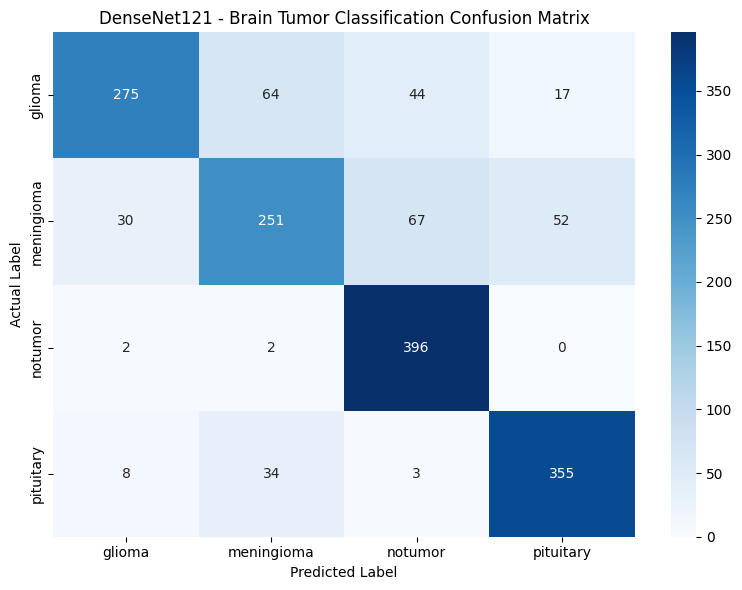

In [63]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Define class names in the correct order
class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("DenseNet121 - Brain Tumor Classification Confusion Matrix")

plt.tight_layout()
plt.show()

In [64]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Define class names in the correct order
class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Calculate sensitivity and specificity for each class
for i, class_name in enumerate(class_names):

    # True Positives
    tp = cm[i, i]

    # False Negatives
    fn = cm[i, :].sum() - tp

    # False Positives
    fp = cm[:, i].sum() - tp

    # True Negatives
    tn = cm.sum() - (tp + fn + fp)

    # Sensitivity (Recall)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0

    # Specificity
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    print(f"\nClass: {class_name}")
    print(f"Sensitivity: {sensitivity * 100:.2f}%")
    print(f"Specificity: {specificity * 100:.2f}%")


Class: glioma
Sensitivity: 68.75%
Specificity: 96.67%

Class: meningioma
Sensitivity: 62.75%
Specificity: 91.67%

Class: notumor
Sensitivity: 99.00%
Specificity: 90.50%

Class: pituitary
Sensitivity: 88.75%
Specificity: 94.25%


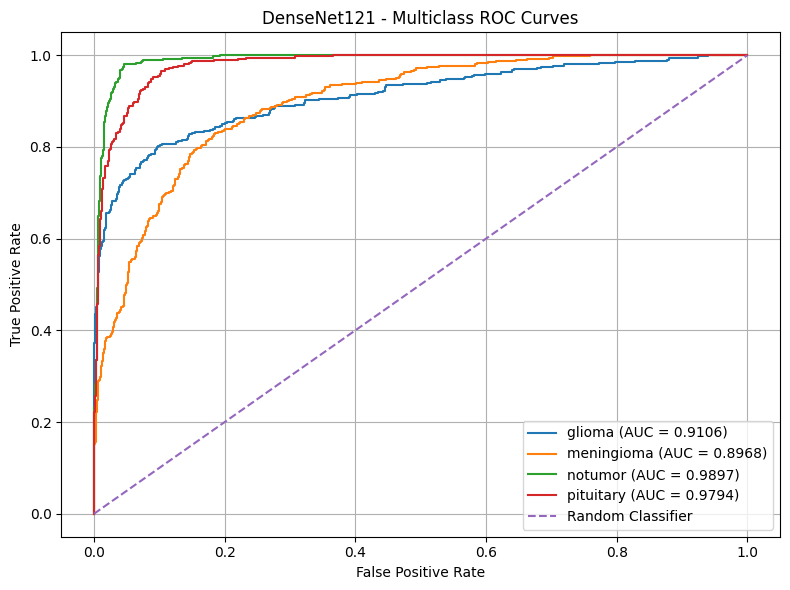

Macro-Average ROC-AUC: 0.9441


In [65]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score, auc
from sklearn.preprocessing import label_binarize

# Define class names in the correct order
class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Convert actual labels into a binary format
y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3])

# Convert predicted probabilities to a NumPy array
y_prob = np.array(y_prob)

# Plot ROC curves
plt.figure(figsize=(8, 6))

for i, class_name in enumerate(class_names):

    # Calculate False Positive Rate and True Positive Rate
    fpr, tpr, thresholds = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    # Calculate AUC
    auc_score = auc(fpr, tpr)

    # Plot ROC curve for this class
    plt.plot(
        fpr,
        tpr,
        label=f'{class_name} (AUC = {auc_score:.4f})'
    )

# Plot random classifier baseline
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('DenseNet121 - Multiclass ROC Curves')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

# Calculate overall multiclass AUC
macro_auc = roc_auc_score(
    y_true,
    y_prob,
    multi_class='ovr',
    average='macro'
)

print(f'Macro-Average ROC-AUC: {macro_auc:.4f}')

In [66]:
# AUC Score
print(f"AUC Score : {auc_score:.4f}")

AUC Score : 0.9794


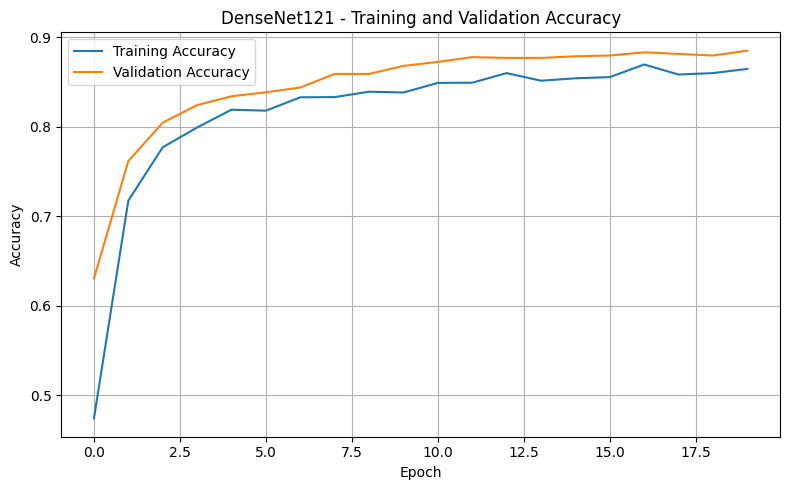

In [67]:
import matplotlib.pyplot as plt

# Training and Validation Accuracy Curve
plt.figure(figsize=(8, 5))

plt.plot(train_acc_history, label="Training Accuracy")
plt.plot(val_acc_history, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DenseNet121 - Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


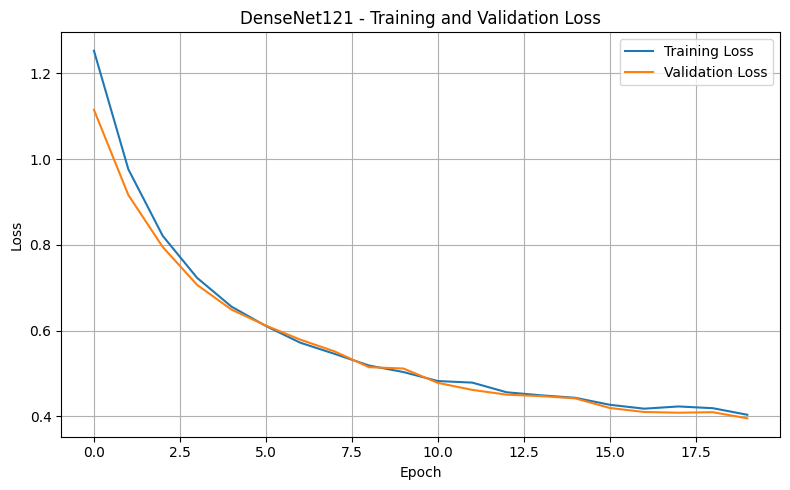

In [68]:
import matplotlib.pyplot as plt

# Training and Validation Loss Curve
plt.figure(figsize=(8, 5))

plt.plot(train_loss_history, label="Training Loss")
plt.plot(val_loss_history, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DenseNet121 - Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()